# DL Tau imaging with kine (A matrix)

**Author:** Felix Ogon & kine coded used

This notebook images the DL Tau protoplanetary disk directly from the ALMA visibility table
`DL_Tau_selfcal_cont_bin60s_1chan_1freq.txt`, without converting it to an ehtim Obsdata object.

Steps:
1. Stokes I and its uncertainty from XX and YY (thesis Eqs. 2.10–2.11)
2. Image grid from the resolution (thesis Eq. 2.2)
3. Dense Fourier matrix A from ehtim (`ftmatrix`)
4. kine neural field: warm start on a blurred disk, then training on the visibilities
5. Experiments that each change one setting of the baseline run

All code cells were written by Felix Ogon. The neural field, training step, coordinate grid and
initial image come from kine (Marianna Foschi, Antonio Fuentes, Brandon Zhao), and the A matrix from ehtim.

In [13]:
# copied from kine's colab_example_static_imaging notebook
!pip install git+https://github.com/mariannafoschi/kine.git
!pip install jax[cuda12] -f https://storage.googleapis.com/jax-releases/jax_cuda_releases.html
!pip install ehtim finufft flax optax

# Flax older than 0.12 does not work with JAX 0.11 or newer
!pip install --no-deps "flax==0.12.10"

  Cloning https://github.com/mariannafoschi/kine.git to /tmp/pip-req-build-wkuo3a7v
  Running command git clone --filter=blob:none --quiet https://github.com/mariannafoschi/kine.git /tmp/pip-req-build-wkuo3a7v
  Resolved https://github.com/mariannafoschi/kine.git to commit 0a68127da08c778727bb8b28677dc0625decd0a2
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Looking in links: https://storage.googleapis.com/jax-releases/jax_cuda_releases.html
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 532.5/532.5 kB 14.3 MB/s  0:00:00
  Attempting uninstall: flax
    Found existing installation: flax 0.11.2
    Uninstalling flax-0.11.2:
      Successfully uninstalled flax-0.11.2


In [17]:
import glob
import numpy as np
import ehtim as eh
import ehtim.const_def as ehc
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage
from tqdm.notebook import tqdm
from collections import OrderedDict as odict

import jax
import optax
from flax import linen as nn
from jax import numpy as jnp

import kine.model as mo
import kine.obsdata as ob
import kine.trainer as tr
import kine.utils as ut
import kine.video as vi

print("✓ All imports successful")

# Fix jax version issue (Only needed in Colab)
if not hasattr(jax, 'tree_map'):
    jax.tree_map = jax.tree.map

# Additional imports
import os
import time
import shutil
import pandas as pd
from matplotlib.colors import LogNorm
from ehtim.observing.obs_helpers import ftmatrix

✓ All imports successful


In [2]:
fname = 'DL_Tau_selfcal_cont_bin60s_1chan_1freq.txt'

In [3]:
data = np.loadtxt(fname, skiprows=1)

u = data[:, 4]
v = data[:, 5]
XX = data[:, 6] + 1j * data[:, 7]
YY = data[:, 8] + 1j * data[:, 9]
weight_XX = data[:, 10]
weight_YY = data[:, 11]

# Stokes I, thesis Eq. 2.10-2.11
vis_I = (XX + YY) / 2

# weights are 1 / sigma^2
sigma_I = 0.5 * np.sqrt(1 / weight_XX + 1 / weight_YY)

print('Number of visibilities:', len(vis_I))

Number of visibilities: 6486


In [4]:
uv_dist = np.sqrt(u**2 + v**2)

order = np.argsort(uv_dist)
shortest = order[0:50]
# the shortest baselines see the whole disk, so their amplitude is the total flux
total_flux = np.median(np.abs(vis_I[shortest]))
print('Total flux (Jy):', total_flux)

Total flux (Jy): 0.1532413121753233


In [18]:
MAS = np.pi / 180 / 3600 / 1000

# thesis Eq. 2.2, u and v are in wavelengths
resolution = 1 / uv_dist.max()
largest_scale = 1 / uv_dist.min()
print('Resolution (mas):', resolution / MAS)
print('Largest scale (arcsec):', largest_scale / MAS / 1000)

fov_mas = 2400
npix = 128

psize = fov_mas * MAS / npix
print('Image:', npix, 'x', npix, 'pixels | pixel size (mas):', psize / MAS)

Resolution (mas): 93.57321864508955
Largest scale (arcsec): 14.314194474773249
Image: 128 x 128 pixels | pixel size (mas): 18.75


In [6]:
uv_points = np.column_stack((u, v))
A = ftmatrix(psize, npix, npix, uv_points)
A = A.astype(np.complex64)
print('A matrix shape:', A.shape)

# kine expects A with shape (1, number of visibilities, number of pixels)
A_kine = A.reshape(1, A.shape[0], A.shape[1])

kine_data = {
    'visI': {
        'target': jnp.array(vis_I, dtype=jnp.complex64),
        'sigma': jnp.array(sigma_I, dtype=jnp.float32),
        'A': jnp.array(A_kine),
    }
}

del A, A_kine

half = fov_mas / 2000
extent = [half, -half, -half, half]

A matrix shape: (6486, 16384)


In [10]:
outdir = 'results'
os.makedirs(outdir, exist_ok=True)

grid = jnp.array(ut.get_grid(npix, npix))


def make_init_image(fwhm_mas):
    # kine's add_tophat expects sizes in microarcseconds
    init_params = {'fwhm': fwhm_mas * 1000, 'blur': 100000, 'posx': 0, 'posy': 0}
    init_im = vi.Image(npix, fov_mas * MAS, 4.5609, 25.3439, 1)
    init_im.add_tophat(total_flux, init_params)
    return jnp.array(init_im.iarr, dtype=jnp.float32)


def create_state(settings):
    network = mo.NeuralField(
        posenc_deg=settings['posenc'],
        outdim=1,
        depth=settings['depth'],
        width=settings['width'],
        activ=nn.gelu,
        outactiv=nn.softplus,
        outshift=10,
        scaling_i=1,
    )
    key = jax.random.PRNGKey(settings['seed'])
    variables = network.init(key, jnp.ones(2), train=True)

    drop = {settings['init_iters']: 0.1}
    schedule = optax.piecewise_constant_schedule(settings['learning_rate'], drop)

    state = tr.Trainer.create(
        apply_fn=network.apply,
        params=variables['params'],
        batch_stats=variables['batch_stats'],
        tx=optax.adamax(schedule),
    )
    return state


def run(settings):
    state = create_state(settings)
    init_image = make_init_image(settings['init_fwhm'])

    # warm start
    for i in range(settings['init_iters']):
        inputs = odict(state=state, grid=grid, init_arr=init_image)
        loss, terms, output, state = tr.Trainer.train_step(inputs)
    print('  warm start done')

    # training
    start = time.time()
    for i in range(settings['train_iters']):
        inputs = odict(state=state, grid=grid, data=kine_data, lcurve=None)
        loss, terms, output, state = tr.Trainer.train_step(inputs)
        if i % 500 == 0:
            print('  iteration', i, '| chi2:', round(float(terms['visI']), 3))
    chi2 = float(terms['visI'])
    end = time.time()
    ms_per_iter = (end - start) / settings['train_iters'] * 1000

    image = np.array(output[:, 0])
    image = image.reshape(npix, npix)
    return image, chi2, ms_per_iter

In [8]:
results = {}

In [11]:
# Baseline
settings = {
    'depth': 4,
    'width': 256,
    'posenc': (0, 0),
    'learning_rate': 1e-2,
    'init_iters': 500,
    'train_iters': 3000,
    'init_fwhm': 800,
    'seed': 1,
}

image, chi2, ms_per_iter = run(settings)
np.save(outdir + '/base.npy', image)

flux = np.sum(image)
results['base'] = {'chi2': chi2, 'flux': flux, 'ms_per_iter': ms_per_iter}
print('base | chi2:', round(chi2, 3), '| flux:', round(flux, 4), '| ms/iter:', round(ms_per_iter, 1))

  warm start done
  iteration 0 | chi2: 60.232
  iteration 500 | chi2: 3.744
  iteration 1000 | chi2: 3.597
  iteration 1500 | chi2: 3.503
  iteration 2000 | chi2: 3.49
  iteration 2500 | chi2: 3.422
base | chi2: 3.384 | flux: 0.1612 | ms/iter: 17.6


In [12]:
# Positional encoding 1
settings = {
    'depth': 4,
    'width': 256,
    'posenc': (1, 1),
    'learning_rate': 1e-2,
    'init_iters': 500,
    'train_iters': 3000,
    'init_fwhm': 800,
    'seed': 1,
}

image, chi2, ms_per_iter = run(settings)
np.save(outdir + '/posenc1.npy', image)

flux = np.sum(image)
results['posenc1'] = {'chi2': chi2, 'flux': flux, 'ms_per_iter': ms_per_iter}
print('posenc1 | chi2:', round(chi2, 3), '| flux:', round(flux, 4), '| ms/iter:', round(ms_per_iter, 1))

  warm start done
  iteration 0 | chi2: 65.338
  iteration 500 | chi2: 3.681
  iteration 1000 | chi2: 3.526
  iteration 1500 | chi2: 3.456
  iteration 2000 | chi2: 3.404
  iteration 2500 | chi2: 3.368
posenc1 | chi2: 3.341 | flux: 0.1614 | ms/iter: 18.2


In [13]:
# Positional encoding 2
settings = {
    'depth': 4,
    'width': 256,
    'posenc': (2, 2),
    'learning_rate': 1e-2,
    'init_iters': 500,
    'train_iters': 3000,
    'init_fwhm': 800,
    'seed': 1,
}

image, chi2, ms_per_iter = run(settings)
np.save(outdir + '/posenc2.npy', image)

flux = np.sum(image)
results['posenc2'] = {'chi2': chi2, 'flux': flux, 'ms_per_iter': ms_per_iter}
print('posenc2 | chi2:', round(chi2, 3), '| flux:', round(flux, 4), '| ms/iter:', round(ms_per_iter, 1))

  warm start done
  iteration 0 | chi2: 64.479
  iteration 500 | chi2: 3.644
  iteration 1000 | chi2: 3.944
  iteration 1500 | chi2: 3.422
  iteration 2000 | chi2: 3.379
  iteration 2500 | chi2: 3.335
posenc2 | chi2: 3.345 | flux: 0.1619 | ms/iter: 18.1


In [14]:
# 6000 training iterations
settings = {
    'depth': 4,
    'width': 256,
    'posenc': (0, 0),
    'learning_rate': 1e-2,
    'init_iters': 500,
    'train_iters': 6000,
    'init_fwhm': 800,
    'seed': 1,
}

image, chi2, ms_per_iter = run(settings)
np.save(outdir + '/iters6k.npy', image)

flux = np.sum(image)
results['iters6k'] = {'chi2': chi2, 'flux': flux, 'ms_per_iter': ms_per_iter}
print('iters6k | chi2:', round(chi2, 3), '| flux:', round(flux, 4), '| ms/iter:', round(ms_per_iter, 1))

  warm start done
  iteration 0 | chi2: 60.232
  iteration 500 | chi2: 3.744
  iteration 1000 | chi2: 3.597
  iteration 1500 | chi2: 3.503
  iteration 2000 | chi2: 3.49
  iteration 2500 | chi2: 3.422
  iteration 3000 | chi2: 3.38
  iteration 3500 | chi2: 3.615
  iteration 4000 | chi2: 3.336
  iteration 4500 | chi2: 3.328
  iteration 5000 | chi2: 3.382
  iteration 5500 | chi2: 3.31
iters6k | chi2: 3.357 | flux: 0.1587 | ms/iter: 18.1


In [15]:
names = ['base', 'posenc1', 'posenc2', 'iters6k']

rows = []
for name in names:
    rows.append([name, results[name]['chi2'], results[name]['flux'], results[name]['ms_per_iter']])

table = pd.DataFrame(rows, columns=['name', 'chi2', 'flux', 'ms_per_iter'])
table.to_csv(outdir + '/results.csv', index=False)
print(table)

      name      chi2      flux  ms_per_iter
0     base  3.383877  0.161237    17.626073
1  posenc1  3.340607  0.161392    18.161119
2  posenc2  3.344870  0.161929    18.072789
3  iters6k  3.357120  0.158667    18.146558


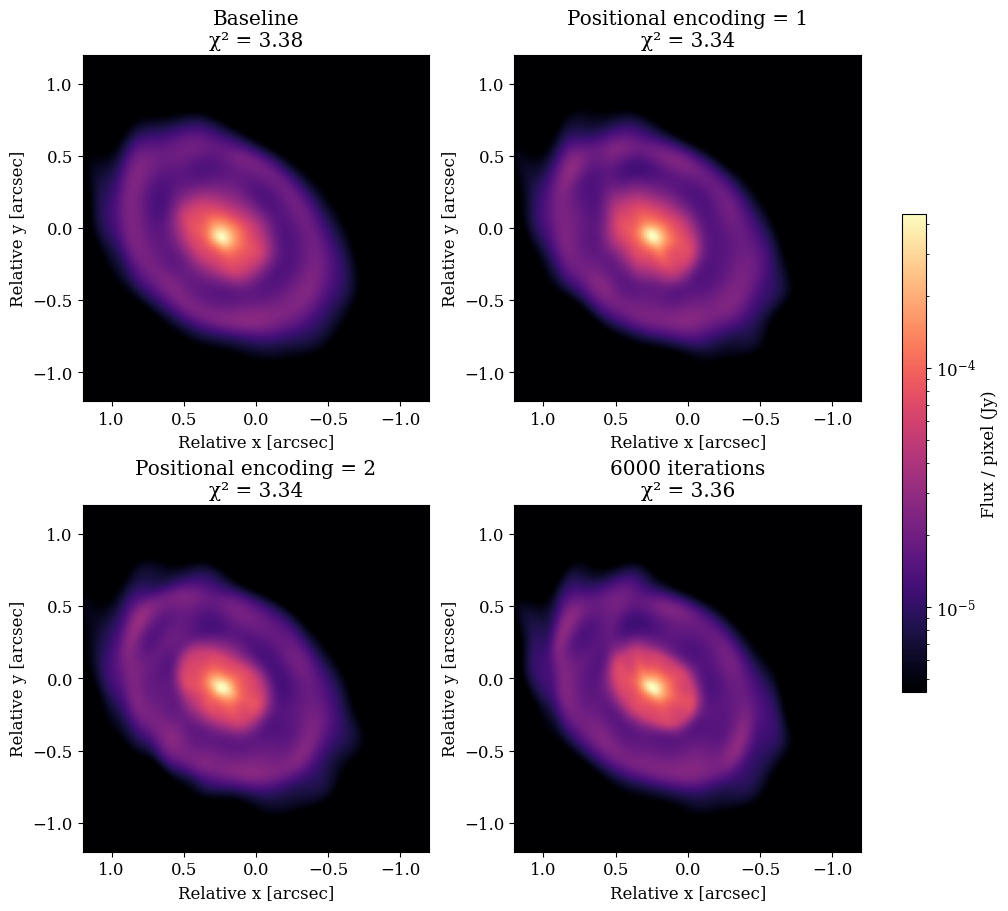

In [16]:
table = pd.read_csv(outdir + '/results.csv')

titles = {
    'base': 'Baseline',
    'posenc1': 'Positional encoding = 1',
    'posenc2': 'Positional encoding = 2',
    'iters6k': '6000 iterations',
}

base_image = np.load(outdir + '/base.npy')
peak = base_image.max()
norm = LogNorm(vmin=0.01 * peak, vmax=peak, clip=True)

fig, ax = plt.subplots(2, 2, figsize=(10, 9), constrained_layout=True)

for i in range(len(table)):
    name = table['name'][i]
    chi2 = table['chi2'][i]
    image = np.load(outdir + '/' + name + '.npy')

    row = i // 2
    col = i % 2
    plot = ax[row, col].imshow(image, extent=extent, cmap='magma', norm=norm)
    ax[row, col].set_title(titles[name] + '\nχ² = ' + str(round(chi2, 2)))
    ax[row, col].set_xlabel('Relative x [arcsec]')
    ax[row, col].set_ylabel('Relative y [arcsec]')

fig.colorbar(plot, ax=ax, label='Flux / pixel (Jy)', shrink=0.6)
plt.savefig(outdir + '/all_runs.png', dpi=150)
plt.show()